# Import Libraries 

In [119]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.preprocessing import LabelEncoder


In [88]:
df = pd.read_csv("StudentPerformanceFactors.csv")

# Load the Dataset 

In [3]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [4]:
df.shape

(6607, 20)

In [5]:
df.columns

Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='object')

# Understand the Dataset 

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [7]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [8]:
df.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

# Data Cleaning

In [59]:
df.dtypes

_h_o_u_r_s___s_t_u_d_i_e_d_                               int64
_a_t_t_e_n_d_a_n_c_e_                                     int64
_p_a_r_e_n_t_a_l___i_n_v_o_l_v_e_m_e_n_t_                object
_a_c_c_e_s_s___t_o___r_e_s_o_u_r_c_e_s_                  object
_e_x_t_r_a_c_u_r_r_i_c_u_l_a_r___a_c_t_i_v_i_t_i_e_s_    object
_s_l_e_e_p___h_o_u_r_s_                                   int64
_p_r_e_v_i_o_u_s___s_c_o_r_e_s_                           int64
_m_o_t_i_v_a_t_i_o_n___l_e_v_e_l_                        object
_i_n_t_e_r_n_e_t___a_c_c_e_s_s_                          object
_t_u_t_o_r_i_n_g___s_e_s_s_i_o_n_s_                       int64
_f_a_m_i_l_y___i_n_c_o_m_e_                              object
_t_e_a_c_h_e_r___q_u_a_l_i_t_y_                          object
_s_c_h_o_o_l___t_y_p_e_                                  object
_p_e_e_r___i_n_f_l_u_e_n_c_e_                            object
_p_h_y_s_i_c_a_l___a_c_t_i_v_i_t_y_                       int64
_l_e_a_r_n_i_n_g___d_i_s_a_b_i_l_i_t_i_e

In [17]:
df["Hours_Studied"]>10
df 

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


In [20]:
df = df.drop_duplicates() 
df

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


In [90]:
df.columns = (
    df.columns 
    .str.strip() 
    .str.lower() 
    .str.replace("","_",regex=True)
) 

print(df.columns.tolist())

['_h_o_u_r_s___s_t_u_d_i_e_d_', '_a_t_t_e_n_d_a_n_c_e_', '_p_a_r_e_n_t_a_l___i_n_v_o_l_v_e_m_e_n_t_', '_a_c_c_e_s_s___t_o___r_e_s_o_u_r_c_e_s_', '_e_x_t_r_a_c_u_r_r_i_c_u_l_a_r___a_c_t_i_v_i_t_i_e_s_', '_s_l_e_e_p___h_o_u_r_s_', '_p_r_e_v_i_o_u_s___s_c_o_r_e_s_', '_m_o_t_i_v_a_t_i_o_n___l_e_v_e_l_', '_i_n_t_e_r_n_e_t___a_c_c_e_s_s_', '_t_u_t_o_r_i_n_g___s_e_s_s_i_o_n_s_', '_f_a_m_i_l_y___i_n_c_o_m_e_', '_t_e_a_c_h_e_r___q_u_a_l_i_t_y_', '_s_c_h_o_o_l___t_y_p_e_', '_p_e_e_r___i_n_f_l_u_e_n_c_e_', '_p_h_y_s_i_c_a_l___a_c_t_i_v_i_t_y_', '_l_e_a_r_n_i_n_g___d_i_s_a_b_i_l_i_t_i_e_s_', '_p_a_r_e_n_t_a_l___e_d_u_c_a_t_i_o_n___l_e_v_e_l_', '_d_i_s_t_a_n_c_e___f_r_o_m___h_o_m_e_', '_g_e_n_d_e_r_', '_e_x_a_m___s_c_o_r_e_']


In [89]:
df.columns

Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='object')

In [78]:
df.head()

,_h_o_u_r_s___s_t_u_d_i_e_d_,_a_t_t_e_n_d_a_n_c_e_,_p_a_r_e_n_t_a_l___i_n_v_o_l_v_e_m_e_n_t_,_a_c_c_e_s_s___t_o___r_e_s_o_u_r_c_e_s_,_e_x_t_r_a_c_u_r_r_i_c_u_l_a_r___a_c_t_i_v_i_t_i_e_s_,_s_l_e_e_p___h_o_u_r_s_,_p_r_e_v_i_o_u_s___s_c_o_r_e_s_,_m_o_t_i_v_a_t_i_o_n___l_e_v_e_l_,_i_n_t_e_r_n_e_t___a_c_c_e_s_s_,_t_u_t_o_r_i_n_g___s_e_s_s_i_o_n_s_,_f_a_m_i_l_y___i_n_c_o_m_e_,_t_e_a_c_h_e_r___q_u_a_l_i_t_y_,_s_c_h_o_o_l___t_y_p_e_,_p_e_e_r___i_n_f_l_u_e_n_c_e_,_p_h_y_s_i_c_a_l___a_c_t_i_v_i_t_y_,_l_e_a_r_n_i_n_g___d_i_s_a_b_i_l_i_t_i_e_s_,_p_a_r_e_n_t_a_l___e_d_u_c_a_t_i_o_n___l_e_v_e_l_,_d_i_s_t_a_n_c_e___f_r_o_m___h_o_m_e_,_g_e_n_d_e_r_,_e_x_a_m___s_c_o_r_e_
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [91]:
print(df["_h_o_u_r_s___s_t_u_d_i_e_d_"].head())


0    23
1    19
2    24
3    29
4    19
Name: _h_o_u_r_s___s_t_u_d_i_e_d_, dtype: int64


In [104]:
numeric_columns = df.select_dtypes(include="number").columns



In [98]:
print(numeric_columns)

Index(['_h_o_u_r_s___s_t_u_d_i_e_d_', '_a_t_t_e_n_d_a_n_c_e_',
       '_s_l_e_e_p___h_o_u_r_s_', '_p_r_e_v_i_o_u_s___s_c_o_r_e_s_',
       '_t_u_t_o_r_i_n_g___s_e_s_s_i_o_n_s_',
       '_p_h_y_s_i_c_a_l___a_c_t_i_v_i_t_y_', '_e_x_a_m___s_c_o_r_e_'],
      dtype='object')


In [107]:
print(df[numeric_columns].dtypes)

_h_o_u_r_s___s_t_u_d_i_e_d_            int64
_a_t_t_e_n_d_a_n_c_e_                  int64
_s_l_e_e_p___h_o_u_r_s_                int64
_p_r_e_v_i_o_u_s___s_c_o_r_e_s_        int64
_t_u_t_o_r_i_n_g___s_e_s_s_i_o_n_s_    int64
_p_h_y_s_i_c_a_l___a_c_t_i_v_i_t_y_    int64
_e_x_a_m___s_c_o_r_e_                  int64
dtype: object


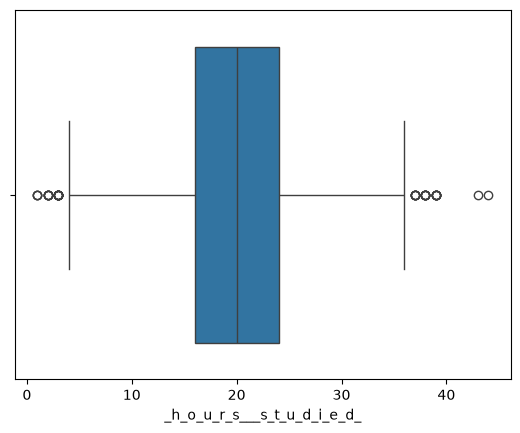

In [135]:
sns.boxplot(x=df["_h_o_u_r_s___s_t_u_d_i_e_d_"]) 
plt.show()

In [116]:
print("\nCleaned shape:",df.shape) 

df.head()


Cleaned shape: (6607, 20)


,_h_o_u_r_s___s_t_u_d_i_e_d_,_a_t_t_e_n_d_a_n_c_e_,_p_a_r_e_n_t_a_l___i_n_v_o_l_v_e_m_e_n_t_,_a_c_c_e_s_s___t_o___r_e_s_o_u_r_c_e_s_,_e_x_t_r_a_c_u_r_r_i_c_u_l_a_r___a_c_t_i_v_i_t_i_e_s_,_s_l_e_e_p___h_o_u_r_s_,_p_r_e_v_i_o_u_s___s_c_o_r_e_s_,_m_o_t_i_v_a_t_i_o_n___l_e_v_e_l_,_i_n_t_e_r_n_e_t___a_c_c_e_s_s_,_t_u_t_o_r_i_n_g___s_e_s_s_i_o_n_s_,_f_a_m_i_l_y___i_n_c_o_m_e_,_t_e_a_c_h_e_r___q_u_a_l_i_t_y_,_s_c_h_o_o_l___t_y_p_e_,_p_e_e_r___i_n_f_l_u_e_n_c_e_,_p_h_y_s_i_c_a_l___a_c_t_i_v_i_t_y_,_l_e_a_r_n_i_n_g___d_i_s_a_b_i_l_i_t_i_e_s_,_p_a_r_e_n_t_a_l___e_d_u_c_a_t_i_o_n___l_e_v_e_l_,_d_i_s_t_a_n_c_e___f_r_o_m___h_o_m_e_,_g_e_n_d_e_r_,_e_x_a_m___s_c_o_r_e_
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [120]:
df.select_dtypes(include='object').columns

Index(['_p_a_r_e_n_t_a_l___i_n_v_o_l_v_e_m_e_n_t_',
       '_a_c_c_e_s_s___t_o___r_e_s_o_u_r_c_e_s_',
       '_e_x_t_r_a_c_u_r_r_i_c_u_l_a_r___a_c_t_i_v_i_t_i_e_s_',
       '_m_o_t_i_v_a_t_i_o_n___l_e_v_e_l_', '_i_n_t_e_r_n_e_t___a_c_c_e_s_s_',
       '_f_a_m_i_l_y___i_n_c_o_m_e_', '_t_e_a_c_h_e_r___q_u_a_l_i_t_y_',
       '_s_c_h_o_o_l___t_y_p_e_', '_p_e_e_r___i_n_f_l_u_e_n_c_e_',
       '_l_e_a_r_n_i_n_g___d_i_s_a_b_i_l_i_t_i_e_s_',
       '_p_a_r_e_n_t_a_l___e_d_u_c_a_t_i_o_n___l_e_v_e_l_',
       '_d_i_s_t_a_n_c_e___f_r_o_m___h_o_m_e_', '_g_e_n_d_e_r_'],
      dtype='object')

In [121]:
le = LabelEncoder()

In [124]:
for col in df.select_dtypes(include='object').columns: 
    df[col] = le.fit_transform(df[col].astype(str))

In [125]:
df.head()

,_h_o_u_r_s___s_t_u_d_i_e_d_,_a_t_t_e_n_d_a_n_c_e_,_p_a_r_e_n_t_a_l___i_n_v_o_l_v_e_m_e_n_t_,_a_c_c_e_s_s___t_o___r_e_s_o_u_r_c_e_s_,_e_x_t_r_a_c_u_r_r_i_c_u_l_a_r___a_c_t_i_v_i_t_i_e_s_,_s_l_e_e_p___h_o_u_r_s_,_p_r_e_v_i_o_u_s___s_c_o_r_e_s_,_m_o_t_i_v_a_t_i_o_n___l_e_v_e_l_,_i_n_t_e_r_n_e_t___a_c_c_e_s_s_,_t_u_t_o_r_i_n_g___s_e_s_s_i_o_n_s_,_f_a_m_i_l_y___i_n_c_o_m_e_,_t_e_a_c_h_e_r___q_u_a_l_i_t_y_,_s_c_h_o_o_l___t_y_p_e_,_p_e_e_r___i_n_f_l_u_e_n_c_e_,_p_h_y_s_i_c_a_l___a_c_t_i_v_i_t_y_,_l_e_a_r_n_i_n_g___d_i_s_a_b_i_l_i_t_i_e_s_,_p_a_r_e_n_t_a_l___e_d_u_c_a_t_i_o_n___l_e_v_e_l_,_d_i_s_t_a_n_c_e___f_r_o_m___h_o_m_e_,_g_e_n_d_e_r_,_e_x_a_m___s_c_o_r_e_
0,23,84,1,0,0,7,73,1,1,0,1,2,1,2,3,0,1,2,1,67
1,19,64,1,2,0,8,59,1,1,2,2,2,1,0,4,0,0,1,0,61
2,24,98,2,2,1,7,91,2,1,2,2,2,1,1,4,0,2,2,1,74
3,29,89,1,2,1,8,98,2,1,1,2,2,1,0,4,0,1,1,1,71
4,19,92,2,2,1,6,65,2,1,3,2,0,1,1,4,0,0,2,0,70


In [127]:
df = pd.get_dummies(df, dtype=int)

In [128]:
df.head()

,_h_o_u_r_s___s_t_u_d_i_e_d_,_a_t_t_e_n_d_a_n_c_e_,_p_a_r_e_n_t_a_l___i_n_v_o_l_v_e_m_e_n_t_,_a_c_c_e_s_s___t_o___r_e_s_o_u_r_c_e_s_,_e_x_t_r_a_c_u_r_r_i_c_u_l_a_r___a_c_t_i_v_i_t_i_e_s_,_s_l_e_e_p___h_o_u_r_s_,_p_r_e_v_i_o_u_s___s_c_o_r_e_s_,_m_o_t_i_v_a_t_i_o_n___l_e_v_e_l_,_i_n_t_e_r_n_e_t___a_c_c_e_s_s_,_t_u_t_o_r_i_n_g___s_e_s_s_i_o_n_s_,_f_a_m_i_l_y___i_n_c_o_m_e_,_t_e_a_c_h_e_r___q_u_a_l_i_t_y_,_s_c_h_o_o_l___t_y_p_e_,_p_e_e_r___i_n_f_l_u_e_n_c_e_,_p_h_y_s_i_c_a_l___a_c_t_i_v_i_t_y_,_l_e_a_r_n_i_n_g___d_i_s_a_b_i_l_i_t_i_e_s_,_p_a_r_e_n_t_a_l___e_d_u_c_a_t_i_o_n___l_e_v_e_l_,_d_i_s_t_a_n_c_e___f_r_o_m___h_o_m_e_,_g_e_n_d_e_r_,_e_x_a_m___s_c_o_r_e_
0,23,84,1,0,0,7,73,1,1,0,1,2,1,2,3,0,1,2,1,67
1,19,64,1,2,0,8,59,1,1,2,2,2,1,0,4,0,0,1,0,61
2,24,98,2,2,1,7,91,2,1,2,2,2,1,1,4,0,2,2,1,74
3,29,89,1,2,1,8,98,2,1,1,2,2,1,0,4,0,1,1,1,71
4,19,92,2,2,1,6,65,2,1,3,2,0,1,1,4,0,0,2,0,70


In [129]:
print(df.columns)

Index(['_h_o_u_r_s___s_t_u_d_i_e_d_', '_a_t_t_e_n_d_a_n_c_e_',
       '_p_a_r_e_n_t_a_l___i_n_v_o_l_v_e_m_e_n_t_',
       '_a_c_c_e_s_s___t_o___r_e_s_o_u_r_c_e_s_',
       '_e_x_t_r_a_c_u_r_r_i_c_u_l_a_r___a_c_t_i_v_i_t_i_e_s_',
       '_s_l_e_e_p___h_o_u_r_s_', '_p_r_e_v_i_o_u_s___s_c_o_r_e_s_',
       '_m_o_t_i_v_a_t_i_o_n___l_e_v_e_l_', '_i_n_t_e_r_n_e_t___a_c_c_e_s_s_',
       '_t_u_t_o_r_i_n_g___s_e_s_s_i_o_n_s_', '_f_a_m_i_l_y___i_n_c_o_m_e_',
       '_t_e_a_c_h_e_r___q_u_a_l_i_t_y_', '_s_c_h_o_o_l___t_y_p_e_',
       '_p_e_e_r___i_n_f_l_u_e_n_c_e_', '_p_h_y_s_i_c_a_l___a_c_t_i_v_i_t_y_',
       '_l_e_a_r_n_i_n_g___d_i_s_a_b_i_l_i_t_i_e_s_',
       '_p_a_r_e_n_t_a_l___e_d_u_c_a_t_i_o_n___l_e_v_e_l_',
       '_d_i_s_t_a_n_c_e___f_r_o_m___h_o_m_e_', '_g_e_n_d_e_r_',
       '_e_x_a_m___s_c_o_r_e_'],
      dtype='object')


In [130]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
_h_o_u_r_s___s_t_u_d_i_e_d_,6607.0,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
_a_t_t_e_n_d_a_n_c_e_,6607.0,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
_p_a_r_e_n_t_a_l___i_n_v_o_l_v_e_m_e_n_t_,6607.0,1.220070,0.865634,0.0,0.0,2.0,2.0,2.0
_a_c_c_e_s_s___t_o___r_e_s_o_u_r_c_e_s_,6607.0,1.203421,0.871783,0.0,0.0,2.0,2.0,2.0
_e_x_t_r_a_c_u_r_r_i_c_u_l_a_r___a_c_t_i_v_i_t_i_e_s_,6607.0,0.596035,0.490728,0.0,0.0,1.0,1.0,1.0
_s_l_e_e_p___h_o_u_r_s_,6607.0,7.029060,1.468120,4.0,6.0,7.0,8.0,10.0
_p_r_e_v_i_o_u_s___s_c_o_r_e_s_,6607.0,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
_m_o_t_i_v_a_t_i_o_n___l_e_v_e_l_,6607.0,1.307553,0.782515,0.0,1.0,2.0,2.0,2.0
_i_n_t_e_r_n_e_t___a_c_c_e_s_s_,6607.0,0.924474,0.264258,0.0,1.0,1.0,1.0,1.0
_t_u_t_o_r_i_n_g___s_e_s_s_i_o_n_s_,6607.0,1.493719,1.230570,0.0,1.0,1.0,2.0,8.0


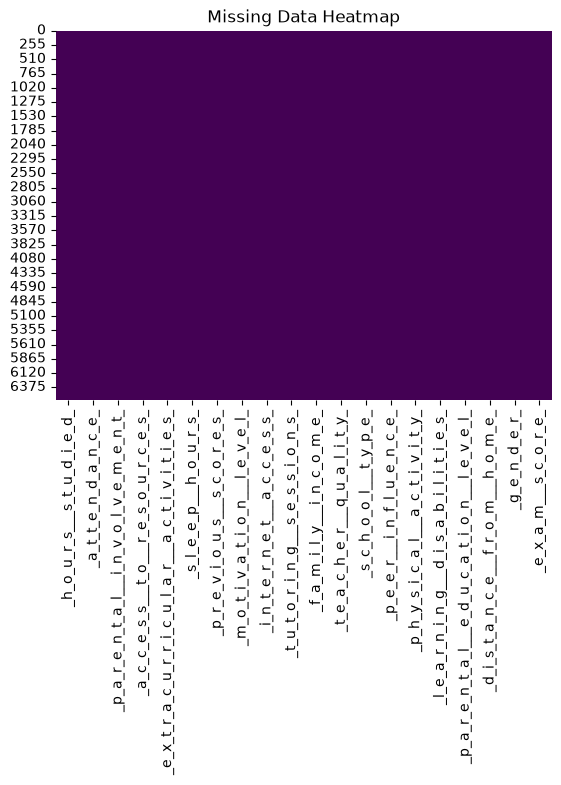

In [136]:
sns.heatmap(df.isnull(),cbar=False, cmap="viridis" ) 

plt.title("Missing Data Heatmap") 
plt.show()

# Student Performance Project Data Cleaning Summary Report 
1.Dataset Overview 

loaded the student performance dataset into data types, column names, dataset structure. 

2.Data Cleaning 

Checked missing values 
checked duplicate records 
standarize column names where required 

3.Categorical Encoding 

Standarized Column names where required 

4.Data Validation 

Used summary statistics to examine numerical columns 
Checked minimum,maximum,mean and median values 
reviewed missing values and duplicate records  

5.Conclusion 

The dataset was inspected,cleaned,and prepared for the student performance factors project.
Categorical features were standarized.  
Summary statistics were used to validate the dataset